In [67]:
import pandas as pd
import requests
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns

In [68]:
def get_all_players(years, teams):
    rolling_df = pd.DataFrame()
    for t in teams:
        for y in years:
            try:
                response = requests.get(f'https://api-web.nhle.com/v1/roster/{t}/{y}')
                if response.status_code == 200:
                  roster = response.json()
                else:
                    print(f'error: response code {response.status_code}')
                forwards = pd.DataFrame(roster['forwards'])
                defense = pd.DataFrame(roster['defensemen'])
                goalies = pd.DataFrame(roster['goalies'])
                all_pos_roster = pd.concat([forwards, defense, goalies])
                all_pos_roster["firstName"] = all_pos_roster["firstName"].apply(lambda x: next(iter(x.values())))
                all_pos_roster["lastName"] = all_pos_roster["lastName"].apply(lambda x: next(iter(x.values())))
                all_pos_roster['season'] = y
                all_pos_roster['team'] = t
                all_pos_roster = all_pos_roster.reset_index()
                all_pos_roster = all_pos_roster.drop(columns = ['index'])
                rolling_df = pd.concat([rolling_df, all_pos_roster])
            except:
                pass
    rolling_df = rolling_df.drop(columns = ['headshot', 'birthCity', 'birthCountry', 'birthStateProvince', 'heightInInches', 'weightInPounds'])
    rolling_df = rolling_df.reindex(columns = ['id', 'season', 'birthDate', 'team', 'firstName', 'lastName','sweaterNumber', 'positionCode', 'shootsCatches','heightInCentimeters', 'weightInKilograms'])
    return rolling_df

In [93]:
all_data = get_all_players(['20262027'], ["ANA", "BOS", "BUF", "CGY", "CAR", "CHI", "COL", "CBJ",
    "DAL", "DET", "EDM", "FLA", "LAK", "MIN", "MTL", "NSH",
    "NJD", "NYI", "NYR", "OTT", "PHI", "PIT", "SJS", "SEA",
    "STL", "TBL", "TOR", "UTA", "VAN", "VGK", "WPG", "WSH"])
all_data.info()

<class 'pandas.DataFrame'>
Index: 797 entries, 0 to 24
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   id                   797 non-null    int64
 1   season               797 non-null    str  
 2   birthDate            797 non-null    str  
 3   team                 797 non-null    str  
 4   firstName            797 non-null    str  
 5   lastName             797 non-null    str  
 6   sweaterNumber        797 non-null    int64
 7   positionCode         797 non-null    str  
 8   shootsCatches        797 non-null    str  
 9   heightInCentimeters  797 non-null    int64
 10  weightInKilograms    797 non-null    int64
dtypes: int64(4), str(7)
memory usage: 74.7 KB


In [ ]:
stats = pd.read_csv('skater_summary.csv')
skaters = pd.read_csv('skaters.csv')
bios = skaters[['id', 'birthDate']]
stats = pd.merge(stats, bios, left_on = 'skaterId', right_on = 'id', how = 'left')
stats['season'] = stats['season'].astype(str)
stats['birthDate'] = pd.to_datetime(stats['birthDate'])
stats['birthDate'] = stats['birthDate'].dt.year
stats['Age'] = stats['season'].str[:4].astype(int) - stats['birthDate']
stats = stats.dropna()
stats['Age'] = stats['Age'].astype(int)
stats = stats.drop(columns = ['id'])

In [96]:
stats.sort_values(by = ['skaterId', 'season'])

,skaterId,season,assists,avgToi,gamesPlayed,goals,pim,plusMinus,points,powerPlayGoals,powerPlayPoints,shootingPctg,shorthandedGoals,shorthandedPoints,shots,birthDate,Age
1153,8470613,20032004,5,13:29,36,1,12,-10,6,0,2,0.029400,0,0,34,1985.0,18
1154,8470613,20052006,12,14:07,72,4,32,-7,16,1,4,0.054800,0,1,73,1985.0,20
1155,8470613,20062007,18,15:48,77,7,26,16,25,3,7,0.064800,0,1,108,1985.0,21
1156,8470613,20072008,28,23:06,82,15,80,12,43,8,19,0.094900,0,1,158,1985.0,22
1157,8470613,20082009,19,22:25,59,8,45,-7,27,4,14,0.054400,0,0,147,1985.0,23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,8485512,20242025,0,7:44,2,0,0,0,0,0,0,0.000000,0,0,2,2001.0,23
98,8485512,20252026,3,12:03,39,2,14,-6,5,0,0,0.060606,0,0,33,2001.0,24
99,8485512,20262027,3,15:20,18,3,8,1,6,0,0,0.157895,0,0,19,2001.0,25
2612,8485702,20252026,13,13:41,44,5,2,-5,18,0,5,0.089286,0,0,56,2000.0,25


In [55]:
teams = pd.merge(all_data, stats, how = 'left', left_on = ['id', 'season'], right_on = ['skaterId', 'season'])
team_rosters = teams[['id', 'season', 'team']]
prev_atoi = stats[stats['season'] == '20252026']
prev_atoi = prev_atoi[['skaterId', 'avgToi']]

In [59]:
team_atoi = pd.merge(team_rosters, prev_atoi, left_on = 'id', right_on = 'skaterId', how = 'left')
team_atoi.sort_values(by = 'id')

,id,season,team,skaterId,avgToi
342,8470613,20252026,COL,8470613.0,18:53
374,8470613,20262027,COL,8470613.0,18:53
677,8470621,20262027,LAK,8470621.0,12:13
676,8470621,20262027,LAK,8470621.0,14:19
1652,8471214,20252026,WSH,8471214.0,17:27
...,...,...,...,...,...
576,8486161,20262027,EDM,NaN,NaN
708,8486166,20252026,MIN,NaN,NaN
1153,8486169,20252026,PIT,NaN,NaN
359,8486171,20262027,COL,NaN,NaN


In [64]:
prev_atoi.sort_values(by = 'skaterId')

,skaterId,avgToi
1174,8470613,18:53
2390,8470621,14:19
2391,8470621,12:13
5953,8471214,17:27
4068,8471215,17:36
...,...,...
4256,8485402,12:49
3894,8485406,17:02
4022,8485414,15:04
98,8485512,12:03


In [62]:
team_rosters.sort_values(by = 'id')

,id,season,team
316,8470613,20252026,COL
340,8470613,20262027,COL
611,8470621,20262027,LAK
1530,8471214,20262027,WSH
1505,8471214,20252026,WSH
...,...,...,...
519,8486161,20262027,EDM
638,8486166,20252026,MIN
1046,8486169,20252026,PIT
327,8486171,20262027,COL


<Axes: xlabel='Age', ylabel='points'>

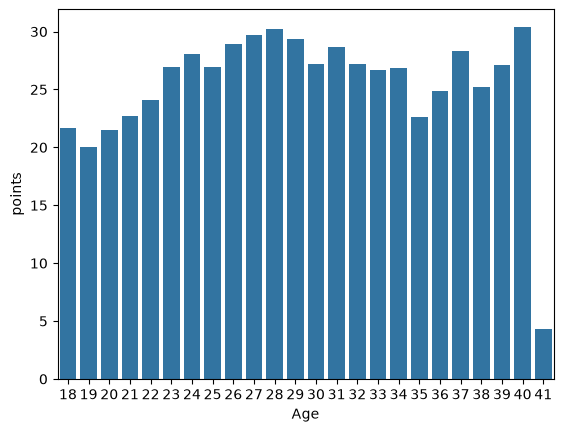

In [12]:
sns.barplot(stats.groupby('Age')['points'].mean())

Performance peaks around 28, with average points increasing about 50% from 18 to 28 years. Performance then steadily decreases every year after that. This equates to roughly a 4% improvement year to year from 18 to 28.

In [6]:
stats

,skaterId,season,assists,avgToi,gamesPlayed,goals,pim,plusMinus,points,powerPlayGoals,powerPlayPoints,shootingPctg,shorthandedGoals,shorthandedPoints,shots,birthDate,Age
0,8484153,20232024,17,18:07,55,12,16,-11,29,4,9,0.110092,0,0,109,2004.0,19
1,8484153,20242025,25,16:14,76,20,14,6,45,4,7,0.175439,1,2,114,2004.0,20
2,8484153,20252026,38,19:09,70,29,33,4,67,4,18,0.150259,2,3,193,2004.0,21
3,8484153,20262027,20,20:15,18,6,6,-2,26,2,17,0.193548,1,1,31,2004.0,22
4,8482118,20232024,0,12:33,3,1,2,0,1,0,0,0.142857,0,0,7,2001.0,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6069,8481030,20232024,1,13:42,14,0,2,0,1,0,0,0.000000,0,0,11,1999.0,24
6070,8481030,20242025,1,16:22,19,0,17,-3,1,0,0,0.000000,0,0,12,1999.0,25
6071,8481030,20252026,7,16:20,20,0,6,4,7,0,0,0.000000,0,0,17,1999.0,26
6072,8481030,20262027,0,13:31,4,0,2,-1,0,0,0,0.000000,0,0,1,1999.0,27


In [13]:
skaters

,id,season,birthDate,team,sweaterNumber,positionCode,shootsCatches,heightInCentimeters,weightInKilograms
0,8484153,20262027,2004-12-26,ANA,91,C,L,191,98
1,8481538,20262027,2001-03-19,ANA,28,R,R,191,100
2,8482118,20262027,2001-12-26,ANA,12,R,R,188,95
3,8483445,20262027,2004-01-19,ANA,61,L,L,188,93
4,8475798,20262027,1992-02-26,ANA,64,C,L,178,87
...,...,...,...,...,...,...,...,...,...
717,8484873,20262027,2006-06-28,WSH,44,D,L,183,82
718,8480043,20262027,1999-04-30,WSH,27,D,R,185,93
719,8478911,20262027,1995-03-01,WSH,3,D,R,188,100
720,8480873,20262027,2000-03-07,WSH,38,D,L,180,86
